# Los Angeles Crime Trends

**Question.** How did weekly incident counts, case status, and time of occurrence differ across Central, Hollywood, and Pacific in 2023?

This notebook adapts a team coursework project and combines the cleaning and exploratory analysis. It uses a filtered download of [City of Los Angeles incident data](https://data.lacity.org/d/2nrs-mtv8).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
data_dir = Path("../data") if Path("../data").is_dir() else Path("data")
raw = pd.read_csv(data_dir / "la-crime-2023.csv", dtype={"dr_no": "string", "time_occ": "string"})
assert 0 < len(raw) < 50_000, "Check for an empty download or an API row cap."

crime = raw.assign(date_occ=pd.to_datetime(raw["date_occ"], format="ISO8601", errors="coerce"))
crime = crime.dropna(subset=["dr_no", "date_occ", "area_name"]).drop_duplicates(subset="dr_no").copy()
clock = crime["time_occ"].str.zfill(4)
valid_clock = clock.str.fullmatch(r"(?:[01]\d|2[0-3])[0-5]\d", na=False)
crime["hour"] = pd.to_numeric(clock.str[:2].where(valid_clock), errors="coerce")
crime["status_desc"] = crime["status_desc"].fillna("Unknown")
assert crime["date_occ"].dt.year.eq(2023).all()
assert set(crime["area_name"]) == {"Central", "Hollywood", "Pacific"}
print(f"{len(crime):,} unique incidents after cleaning ({len(raw) - len(crime):,} rows excluded).")
print(f"{(~valid_clock).sum():,} missing or invalid times excluded from the hourly chart.")

42,206 unique incidents after cleaning (0 rows excluded).
0 missing or invalid times excluded from the hourly chart.


## Weekly counts and status

Use Monday-start weeks and exclude partial weeks at the year boundaries from the weekly plot. Summarize status across the full calendar year.

status_desc,Adult Arrest,Adult Other,Invest Cont,Juv Arrest,Juv Other
area_name,,,,,
Central,958,1263,14714,28,3
Hollywood,836,958,9622,8,24
Pacific,797,769,12196,23,7


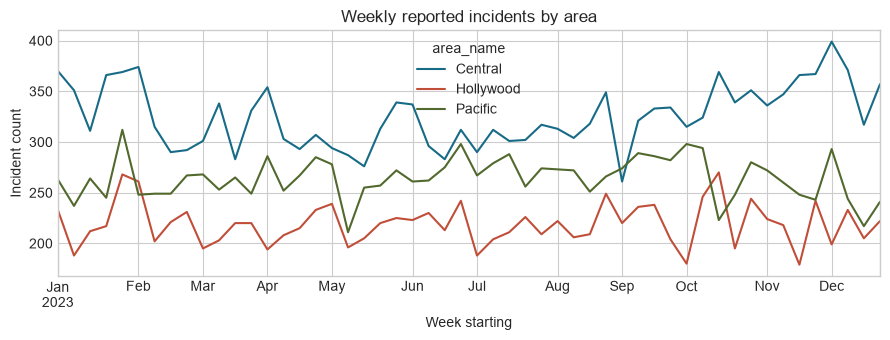

In [2]:
crime["week_start"] = crime["date_occ"].dt.to_period("W-SUN").dt.start_time
full_weeks = pd.date_range("2023-01-02", "2023-12-25", freq="W-MON")
weekly = pd.crosstab(crime["week_start"], crime["area_name"]).reindex(full_weeks, fill_value=0)
status = pd.crosstab(crime["area_name"], crime["status_desc"])
assert status.to_numpy().sum() == len(crime)
display(status)
ax = weekly.plot(figsize=(9, 3.5), color=["#176B87", "#C04E39", "#52692E"])
ax.set(title="Weekly reported incidents by area", xlabel="Week starting", ylabel="Incident count")
plt.tight_layout()
plt.show()

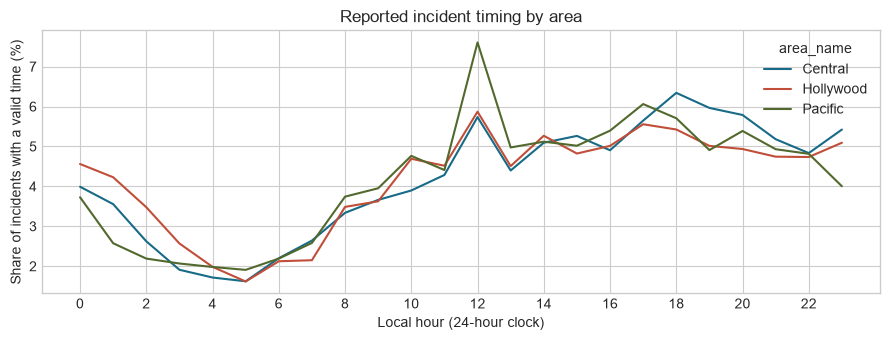

Peak reported hour by area


,Peak hour
area_name,
Central,18
Hollywood,12
Pacific,12


In [3]:
hours = (
    pd.crosstab(crime["hour"], crime["area_name"], normalize="columns")
    .reindex(range(24), fill_value=0)
    .mul(100)
)
assert hours.sum().round(8).eq(100).all()
ax = hours.plot(figsize=(9, 3.5), color=["#176B87", "#C04E39", "#52692E"], xticks=range(0, 24, 2))
ax.set(title="Reported incident timing by area", xlabel="Local hour (24-hour clock)", ylabel="Share of incidents with a valid time (%)")
plt.tight_layout()
plt.show()
print("Peak reported hour by area")
display(hours.idxmax().rename("Peak hour").to_frame())

**Interpretation.** Counts reflect reported records. Differences in area size, population, and reporting practices limit comparisons. Recorded times can include approximate or default entries, so treat hourly peaks as descriptive.